# Limited-overlap results: DUPGT, semantics and LLM teachers (Books → Movies & TV, Amazon 2023)

This notebook gathers every final run into one place for the presentation:

| Batch | Shared users used to train the bridge | Seeds | Models |
|---|---|---|---|
| Full overlap | 100% (89,031) | 2020 | DUPGT, + semantic gate, + LLM / text / shuffled teacher (λ=0.01) |
| Limited overlap | 10% (8,903) | 2020–2022 | same five |
| Scarce overlap | 1% (890) | 2020–2022 | same five, plus all three teachers at λ=0.1 |
| Teacher scale | 1% (890) | 2020–2022 | 1,988-user text-only teacher (no LLM) and its shuffled control, λ=0.1 |

All numbers are **test-set** scores of checkpoints chosen by **validation RMSE**. Each batch was locked
(`transfer-lock`) before scoring. The 2023 test split had been looked at in earlier experiments,
so these are follow-up results rather than a pristine hold-out.

Within one seed, every model sees the *same* real shared users and the *same* starting bridge, so
differences between models are **paired** comparisons.

Figures are also saved as PNGs in `outputs/amazon2023/presentation_figures/` for the slides.

In [1]:
from pathlib import Path
import json, sys, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from summarise_overlap_seeds import collect, summarise, label

ROOTS = [ROOT / "outputs/amazon2023/overlap_seeds",
         ROOT / "outputs/amazon2023/semantic_transfer/full_seed2020",
         ROOT / "outputs/amazon2023/text_teacher_scale"]
FIGURES = ROOT / "outputs/amazon2023/presentation_figures"
FIGURES.mkdir(parents=True, exist_ok=True)

NAMES = {"movie_mean": "Movie average (no transfer)", "dupgt": "DUPGT (baseline)",
         "semantics": "DUPGT + semantic gate",
         "semantics_llm_w0.01": "+ LLM teacher (λ=0.01)", "semantics_text_w0.01": "+ text teacher (λ=0.01)",
         "semantics_shuffled_w0.01": "+ shuffled teacher (λ=0.01)",
         "semantics_llm_w0.1": "+ LLM teacher (λ=0.1)", "semantics_text_w0.1": "+ text teacher (λ=0.1)",
         "semantics_shuffled_w0.1": "+ shuffled teacher (λ=0.1)",
         "semantics_text_only_w0.1": "+ text teacher, 1,988 users (λ=0.1)",
         "semantics_text_only_shuffled_w0.1": "+ shuffled text, 1,988 users (λ=0.1)"}
COLOURS = {"movie_mean": "#8a8a8a", "dupgt": "#222222", "semantics": "#2b6cb0",
           "llm": "#c05621", "text": "#2f855a", "shuffled": "#805ad5", "text_only": "#b7791f"}
def colour(model):
    if model.endswith("text_only_shuffled_w0.1"):
        return "#a0aec0"
    for key in ("text_only", "llm", "shuffled", "text"):
        if f"_{key}_" in model:
            return COLOURS[key]
    return COLOURS.get(model, "#000000")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})
def save(fig, name):
    fig.savefig(FIGURES / f"{name}.png", dpi=180, bbox_inches="tight")

## 1. Collect every scored run
One row per (overlap, seed, model). The movie-average baseline is identical for every run, so it is kept once per group.

In [2]:
rows = pd.DataFrame(collect(ROOTS, "test"))
rows["overlap"] = rows["overlap_fraction"].map(lambda f: f"{f:.0%}")
runs = rows[rows.run != "baseline"]
print(f"{len(runs)} scored model runs, {rows.groupby(['overlap_fraction','seed']).ngroups} (overlap, seed) groups")
display(runs.groupby(["overlap", "model"]).size().unstack(0).fillna(0).astype(int))

50 scored model runs, 7 (overlap, seed) groups


overlap,1%,10%,100%
model,,,
dupgt,3,3,1
semantics,3,3,1
semantics_llm_w0.01,3,3,1
semantics_llm_w0.1,3,0,0
semantics_shuffled_w0.01,3,3,1
semantics_shuffled_w0.1,3,0,0
semantics_text_only_shuffled_w0.1,3,0,0
semantics_text_only_w0.1,3,0,0
semantics_text_w0.01,3,3,1


## 2. Study design
How much real shared-user data each overlap level gives the bridge.

In [3]:
design = (rows.groupby("overlap_fraction")
          .agg(shared_users=("real_users", "first"), real_movie_ratings=("real_ratings", "mean"),
               seeds=("seed", "nunique"))
          .reset_index())
design["overlap"] = design.overlap_fraction.map(lambda f: f"{f:.0%}")
design[["overlap", "shared_users", "real_movie_ratings", "seeds"]].style.format(
    {"shared_users": "{:,}", "real_movie_ratings": "{:,.0f}"}).hide(axis="index")

overlap,shared_users,real_movie_ratings,seeds
1%,890,"14,851",3
10%,"8,903","149,383",3
100%,"89,031","1,497,886",1


## 3. Main results: test error by overlap level
Mean ± standard deviation over seeds (100% has a single seed). Lower is better.

In [4]:
summary, paired = map(pd.DataFrame, summarise(rows.to_dict("records")))
summary["overlap"] = summary.overlap_fraction.map(lambda f: f"{f:.0%}")
summary["Model"] = summary.model.map(NAMES)
def pm(mean, sd):
    return f"{mean:.4f}" if sd != sd else f"{mean:.4f} ± {sd:.4f}"
table = summary.assign(RMSE=[pm(m, s) for m, s in zip(summary.rmse_mean, summary.rmse_sd)],
                       MAE=[pm(m, s) for m, s in zip(summary.mae_mean, summary.mae_sd)])
display(table[["overlap", "Model", "seeds", "RMSE", "MAE"]].rename(columns={"overlap": "Overlap", "seeds": "Seeds"})
        .style.hide(axis="index"))

Overlap,Model,Seeds,RMSE,MAE
1%,Movie average (no transfer),3,1.0507 ± 0.0000,0.7620 ± 0.0000
1%,DUPGT (baseline),3,1.1128 ± 0.0171,0.8146 ± 0.0132
1%,DUPGT + semantic gate,3,1.0926 ± 0.0168,0.7954 ± 0.0165
1%,+ LLM teacher (λ=0.01),3,1.0954 ± 0.0142,0.7978 ± 0.0129
1%,+ text teacher (λ=0.01),3,1.0955 ± 0.0142,0.7979 ± 0.0128
1%,+ shuffled teacher (λ=0.01),3,1.0953 ± 0.0143,0.7978 ± 0.0129
1%,+ LLM teacher (λ=0.1),3,1.0924 ± 0.0166,0.7967 ± 0.0147
1%,+ text teacher (λ=0.1),3,1.0934 ± 0.0161,0.7970 ± 0.0139
1%,+ shuffled teacher (λ=0.1),3,1.0920 ± 0.0172,0.7963 ± 0.0150
1%,"+ text teacher, 1,988 users (λ=0.1)",3,1.0925 ± 0.0166,0.7959 ± 0.0144


### Headline table (the five-model comparison, λ = 0.01)

In [5]:
core = ["movie_mean", "dupgt", "semantics", "semantics_llm_w0.01", "semantics_text_w0.01", "semantics_shuffled_w0.01"]
headline = summary[summary.model.isin(core)].pivot(index="model", columns="overlap", values="rmse_mean").loc[core]
headline.index = headline.index.map(NAMES)
headline = headline[["1%", "10%", "100%"]]
display(headline.style.format("{:.4f}").highlight_min(axis=0, props="font-weight:bold"))

overlap,1%,10%,100%
model,,,
Movie average (no transfer),1.0507,1.0507,1.0507
DUPGT (baseline),1.1128,1.0301,1.0119
DUPGT + semantic gate,1.0926,1.0258,1.0075
+ LLM teacher (λ=0.01),1.0954,1.0259,1.0074
+ text teacher (λ=0.01),1.0955,1.0259,1.0075
+ shuffled teacher (λ=0.01),1.0953,1.0259,1.0074


## 4. Figure: error against the amount of shared-user data
Error bars are ±1 SD across seeds. The dashed line is the movie average, which uses no transfer at all.

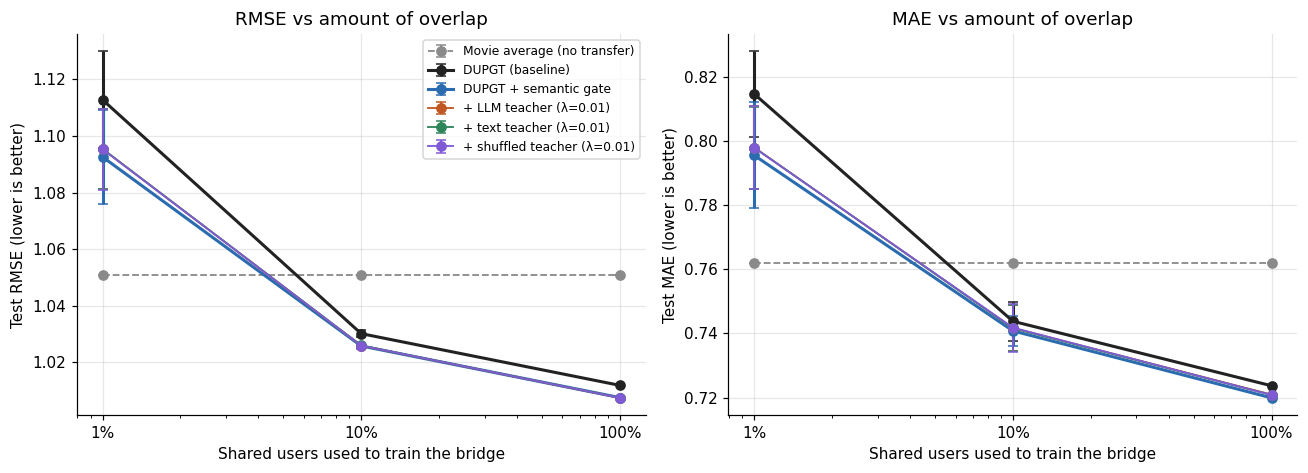

In [6]:
fractions = sorted(summary.overlap_fraction.unique())
fig, axes = plt.subplots(1, 2, figsize=(12, 4.4))
for axis, metric in zip(axes, ("rmse", "mae")):
    for model in ["movie_mean", "dupgt", "semantics", "semantics_llm_w0.01", "semantics_text_w0.01", "semantics_shuffled_w0.01"]:
        part = summary[summary.model == model].sort_values("overlap_fraction")
        axis.errorbar(100 * part.overlap_fraction, part[f"{metric}_mean"], yerr=part[f"{metric}_sd"].fillna(0),
                      label=NAMES[model], color=colour(model), marker="o", capsize=3,
                      linestyle="--" if model == "movie_mean" else "-", linewidth=2 if model in ("dupgt", "semantics") else 1.2)
    axis.set_xscale("log")
    axis.set_xticks([100 * f for f in fractions], [f"{f:.0%}" for f in fractions])
    axis.set(xlabel="Shared users used to train the bridge", ylabel=f"Test {metric.upper()} (lower is better)",
             title=f"{metric.upper()} vs amount of overlap")
axes[0].legend(fontsize=8)
fig.tight_layout(); save(fig, "01_overlap_curve"); plt.show()

**Reading the curve.**
* At **1%** every transfer model is *worse* than simply predicting each movie's average rating.
* By **10%** transfer beats the baseline, and it keeps improving at 100%. The break-even lies between roughly 900 and 9,000 shared users.
* The teacher lines sit on top of the semantic-gate line at every level.

## 5. Paired differences (same seed, same users, same starting bridge)
ΔRMSE = model − reference. **Negative means the model is better.** "Better in" counts the seeds where it won.

In [7]:
paired["overlap"] = paired.overlap_fraction.map(lambda f: f"{f:.0%}")
show = paired.assign(Model=paired.model.map(NAMES), Reference=paired.reference.map(NAMES))
display(show[["overlap", "Model", "Reference", "seeds", "delta_rmse_mean", "delta_rmse_sd", "delta_mae_mean", "model_better_in"]]
        .rename(columns={"overlap": "Overlap", "seeds": "Seeds", "delta_rmse_mean": "Mean ΔRMSE", "delta_rmse_sd": "SD",
                         "delta_mae_mean": "Mean ΔMAE", "model_better_in": "Better in"})
        .style.format({"Mean ΔRMSE": "{:+.5f}", "SD": "{:.5f}", "Mean ΔMAE": "{:+.5f}"}).hide(axis="index"))

Overlap,Model,Reference,Seeds,Mean ΔRMSE,SD,Mean ΔMAE,Better in
1%,DUPGT + semantic gate,DUPGT (baseline),3,-0.02020,0.02734,-0.01912,2/3
1%,+ LLM teacher (λ=0.01),DUPGT + semantic gate,3,+0.00277,0.00417,+0.00240,0/3
1%,+ text teacher (λ=0.01),DUPGT + semantic gate,3,+0.00288,0.00424,+0.00244,0/3
1%,+ shuffled teacher (λ=0.01),DUPGT + semantic gate,3,+0.00274,0.00417,+0.00237,0/3
1%,+ LLM teacher (λ=0.1),DUPGT + semantic gate,3,-0.00023,0.00244,+0.00128,2/3
1%,+ text teacher (λ=0.1),DUPGT + semantic gate,3,+0.00077,0.00262,+0.00151,1/3
1%,+ shuffled teacher (λ=0.1),DUPGT + semantic gate,3,-0.00057,0.00292,+0.00086,1/3
1%,+ LLM teacher (λ=0.01),+ text teacher (λ=0.01),3,-0.00011,0.00008,-0.00004,3/3
1%,+ LLM teacher (λ=0.01),+ shuffled teacher (λ=0.01),3,+0.00003,0.00006,+0.00003,1/3
1%,+ LLM teacher (λ=0.1),+ text teacher (λ=0.1),3,-0.00100,0.00049,-0.00022,3/3


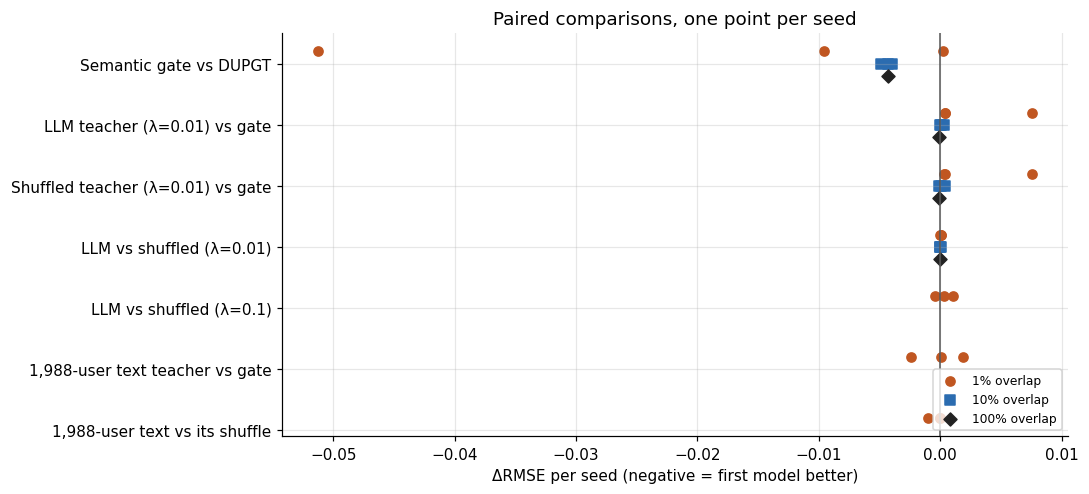

In [8]:
# Per-seed deltas so every point is visible, not just the mean.
lookup = rows.set_index(["overlap_fraction", "seed", "model"])["rmse"]
questions = [("semantics", "dupgt", "Semantic gate vs DUPGT"),
             ("semantics_llm_w0.01", "semantics", "LLM teacher (λ=0.01) vs gate"),
             ("semantics_shuffled_w0.01", "semantics", "Shuffled teacher (λ=0.01) vs gate"),
             ("semantics_llm_w0.01", "semantics_shuffled_w0.01", "LLM vs shuffled (λ=0.01)"),
             ("semantics_llm_w0.1", "semantics_shuffled_w0.1", "LLM vs shuffled (λ=0.1)"),
             ("semantics_text_only_w0.1", "semantics", "1,988-user text teacher vs gate"),
             ("semantics_text_only_w0.1", "semantics_text_only_shuffled_w0.1", "1,988-user text vs its shuffle")]
fig, axis = plt.subplots(figsize=(10, 4.6))
markers = {0.01: "o", 0.1: "s", 1.0: "D"}
for y, (model, reference, text) in enumerate(questions):
    for fraction in fractions:
        values = [lookup[(fraction, s, model)] - lookup[(fraction, s, reference)]
                  for s in sorted(rows.seed.unique())
                  if (fraction, s, model) in lookup.index and (fraction, s, reference) in lookup.index]
        if values:
            offset = {0.01: -0.2, 0.1: 0.0, 1.0: 0.2}[fraction]
            axis.scatter(values, [y + offset] * len(values), marker=markers[fraction], s=36,
                         color={0.01: "#c05621", 0.1: "#2b6cb0", 1.0: "#222222"}[fraction],
                         label=f"{fraction:.0%} overlap" if y == 0 else None)
axis.axvline(0, color="#555555", linewidth=1)
axis.set_yticks(range(len(questions)), [q[2] for q in questions])
axis.invert_yaxis()
axis.set(xlabel="ΔRMSE per seed (negative = first model better)", title="Paired comparisons, one point per seed")
axis.legend(loc="lower right", fontsize=8)
fig.tight_layout(); save(fig, "02_paired_deltas"); plt.show()

**Reading the paired comparisons.**
* **The semantic gate is the only reliable gain.** At 10% it beats DUPGT on all 3 seeds (≈ −0.0044 RMSE, SD ≈ 0.0005), and the gain is similar at 100%. At 1% the mean gain is larger but varies widely between seeds.
* **The LLM teacher's effect is indistinguishable from its controls.** LLM vs shuffled is within ±0.001 at every level. A shuffled profile (another user's interests) helps exactly as much, so whatever the teacher adds is not personal.

## 6. Does more teacher data help? (1% overlap, λ = 0.1)
The text teacher needs no LLM, so it was scaled from 199 to 1,988 source-only users (1,990 → 19,880 pairs). Its first 200 users are exactly the LLM teacher's users.

seed,2020,2021,2022,mean,Δ vs gate
model,,,,,
DUPGT + semantic gate,1.1114,1.0870,1.0794,1.0926,+0.0000
+ LLM teacher (λ=0.1),1.1114,1.0842,1.0815,1.0924,-0.0002
+ text teacher (λ=0.1),1.1119,1.0853,1.0829,1.0934,+0.0008
+ shuffled teacher (λ=0.1),1.1118,1.0832,1.0811,1.0920,-0.0006
"+ text teacher, 1,988 users (λ=0.1)",1.1115,1.0846,1.0812,1.0925,-0.0001
"+ shuffled text, 1,988 users (λ=0.1)",1.1115,1.0847,1.0822,1.0928,+0.0002


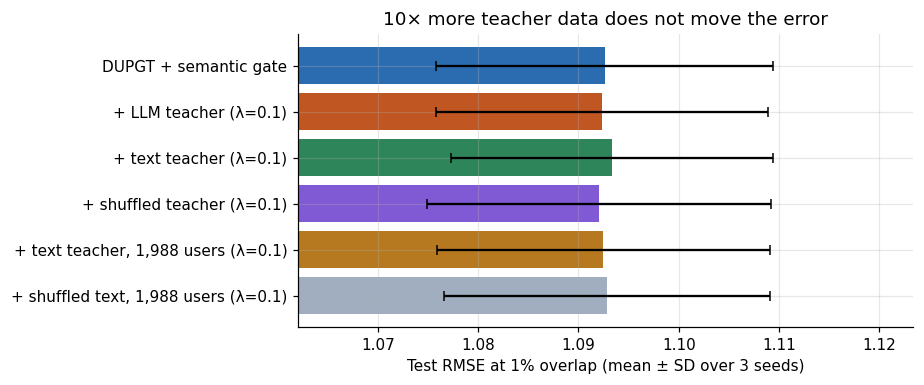

In [9]:
scale_models = ["semantics", "semantics_llm_w0.1", "semantics_text_w0.1", "semantics_shuffled_w0.1",
                "semantics_text_only_w0.1", "semantics_text_only_shuffled_w0.1"]
scale = rows[(rows.overlap_fraction == 0.01) & rows.model.isin(scale_models)]
per_seed = scale.pivot(index="model", columns="seed", values="rmse").loc[scale_models]
per_seed["mean"] = per_seed.mean(axis=1)
per_seed["Δ vs gate"] = per_seed["mean"] - per_seed.loc["semantics", "mean"]
per_seed.index = per_seed.index.map(NAMES)
display(per_seed.style.format("{:.4f}").format("{:+.4f}", subset=["Δ vs gate"]))

fig, axis = plt.subplots(figsize=(8.5, 3.6))
means = scale.groupby("model").rmse.agg(["mean", "std"]).loc[scale_models]
axis.barh(range(len(means)), means["mean"], xerr=means["std"], color=[colour(m) for m in means.index], capsize=3)
axis.set_yticks(range(len(means)), [NAMES[m] for m in means.index]); axis.invert_yaxis()
axis.set_xlim(means["mean"].min() - 0.03, means["mean"].max() + 0.03)
axis.set(xlabel="Test RMSE at 1% overlap (mean ± SD over 3 seeds)", title="10× more teacher data does not move the error")
fig.tight_layout(); save(fig, "03_teacher_scale"); plt.show()

## 7. Negative transfer rate (NTR)
From the proposal: the **fraction of test users whose error is worse with transfer than with the target-only baseline** (movie average). Computed from per-user MAE.

Overlap,Model,NTR,SD,MAE harm when worse,MAE gain when better
1%,DUPGT (baseline),56.3%,1.5%,0.254,0.150
1%,DUPGT + semantic gate,54.3%,1.3%,0.218,0.144
1%,+ LLM teacher (λ=0.01),54.6%,1.0%,0.223,0.146
1%,+ shuffled teacher (λ=0.01),54.6%,1.0%,0.223,0.146
10%,DUPGT (baseline),47.4%,1.4%,0.151,0.147
10%,DUPGT + semantic gate,46.8%,1.2%,0.147,0.148
10%,+ LLM teacher (λ=0.01),46.9%,1.5%,0.147,0.147
10%,+ shuffled teacher (λ=0.01),46.9%,1.6%,0.147,0.147
100%,DUPGT (baseline),42.0%,nan%,0.127,0.144
100%,DUPGT + semantic gate,40.9%,nan%,0.123,0.145


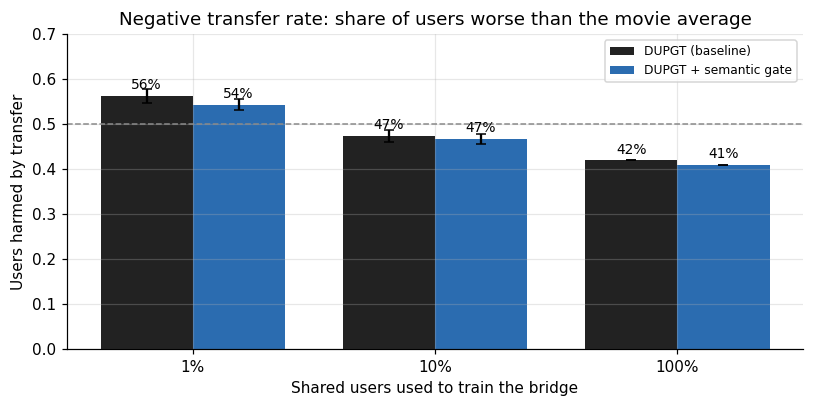

In [10]:
def user_file(run):
    return pd.read_csv(Path(run) / "test_user_metrics.csv")
ntr_rows = []
for _, run in runs.iterrows():
    users = user_file(run.run)
    worse = users.dupgt_minus_movie_mean_mae > 0
    ntr_rows.append({"overlap_fraction": run.overlap_fraction, "seed": run.seed, "model": run.model,
                     "ntr": worse.mean(), "mean_harm_when_worse": users.dupgt_minus_movie_mean_mae[worse].mean(),
                     "mean_gain_when_better": -users.dupgt_minus_movie_mean_mae[~worse].mean()})
ntr = pd.DataFrame(ntr_rows)
ntr_summary = (ntr.groupby(["overlap_fraction", "model"]).agg(ntr=("ntr", "mean"), ntr_sd=("ntr", "std"),
               harm=("mean_harm_when_worse", "mean"), gain=("mean_gain_when_better", "mean")).reset_index())
core_t = ["dupgt", "semantics", "semantics_llm_w0.01", "semantics_shuffled_w0.01"]
view = ntr_summary[ntr_summary.model.isin(core_t)].copy()
view["overlap"] = view.overlap_fraction.map(lambda f: f"{f:.0%}")
view["Model"] = view.model.map(NAMES)
display(view[["overlap", "Model", "ntr", "ntr_sd", "harm", "gain"]]
        .rename(columns={"overlap": "Overlap", "ntr": "NTR", "ntr_sd": "SD", "harm": "MAE harm when worse",
                         "gain": "MAE gain when better"})
        .style.format({"NTR": "{:.1%}", "SD": "{:.1%}", "MAE harm when worse": "{:.3f}", "MAE gain when better": "{:.3f}"})
        .hide(axis="index"))

fig, axis = plt.subplots(figsize=(7.5, 3.8))
width = 0.38
for i, model in enumerate(["dupgt", "semantics"]):
    part = ntr_summary[ntr_summary.model == model].sort_values("overlap_fraction")
    x = np.arange(len(part)) + (i - 0.5) * width
    axis.bar(x, part.ntr, width, yerr=part.ntr_sd.fillna(0), color=colour(model), label=NAMES[model], capsize=3)
    for xi, value in zip(x, part.ntr):
        axis.text(xi, value + 0.015, f"{value:.0%}", ha="center", fontsize=9)
axis.axhline(0.5, color="#8a8a8a", linestyle="--", linewidth=1)
axis.set_xticks(range(len(fractions)), [f"{f:.0%}" for f in fractions])
axis.set(ylim=(0, 0.7), xlabel="Shared users used to train the bridge",
         ylabel="Users harmed by transfer", title="Negative transfer rate: share of users worse than the movie average")
axis.legend(fontsize=8)
fig.tight_layout(); save(fig, "04_negative_transfer_rate"); plt.show()

**Reading the NTR.** Even with all 89,031 shared users, transfer makes roughly **4 in 10** test users worse off than the movie average. Better *average* error hides a large group of users for whom transfer is harmful. DUPGT has no way to notice this and fall back for those users.

## 8. Diagnostic: what goes wrong at 1%?
DUPGT mixes a high-rating (liked) bridge and a low-rating bridge with a per-prediction gate α_high ∈ [0, 1]. The saved predictions include the gate and the user's source history counts.

In [11]:
def predictions(run, columns=("actual_rating", "movie_mean", "dupgt", "alpha_high", "source_high_count", "source_low_count")):
    return pd.read_csv(Path(run) / "test_predictions.csv.gz", usecols=list(columns))
diag = []
gate_samples = {}
for _, run in runs[runs.model.isin(["dupgt", "semantics"])].iterrows():
    p = predictions(run.run)
    diag.append({"overlap_fraction": run.overlap_fraction, "seed": run.seed, "model": run.model,
                 "mean α_high": p.alpha_high.mean(), "SD α_high": p.alpha_high.std(),
                 "bias (pred − actual)": (p.dupgt - p.actual_rating).mean(),
                 "prediction SD": p.dupgt.std(), "movie-average SD": p.movie_mean.std()})
    if run.model == "dupgt":
        gate_samples[(run.overlap_fraction, run.seed)] = p.alpha_high.sample(20000, random_state=0).to_numpy()
diag = pd.DataFrame(diag).sort_values(["model", "overlap_fraction", "seed"])
diag["overlap"] = diag.overlap_fraction.map(lambda f: f"{f:.0%}")
display(diag[["model", "overlap", "seed", "mean α_high", "SD α_high", "bias (pred − actual)", "prediction SD", "movie-average SD"]]
        .style.format({c: "{:.3f}" for c in ["mean α_high", "SD α_high", "bias (pred − actual)", "prediction SD", "movie-average SD"]})
        .hide(axis="index"))

model,overlap,seed,mean α_high,SD α_high,bias (pred − actual),prediction SD,movie-average SD
dupgt,1%,2020,0.000,0.000,-0.059,0.817,0.541
dupgt,1%,2021,0.448,0.150,-0.038,0.796,0.541
dupgt,1%,2022,0.000,0.000,-0.021,0.873,0.541
dupgt,10%,2020,0.725,0.120,-0.010,0.596,0.541
dupgt,10%,2021,0.788,0.101,0.002,0.614,0.541
dupgt,10%,2022,0.788,0.105,-0.003,0.617,0.541
dupgt,100%,2020,0.882,0.071,-0.001,0.615,0.541
semantics,1%,2020,0.000,0.000,-0.062,0.822,0.541
semantics,1%,2021,0.124,0.141,0.000,0.757,0.541
semantics,1%,2022,0.117,0.115,0.008,0.731,0.541


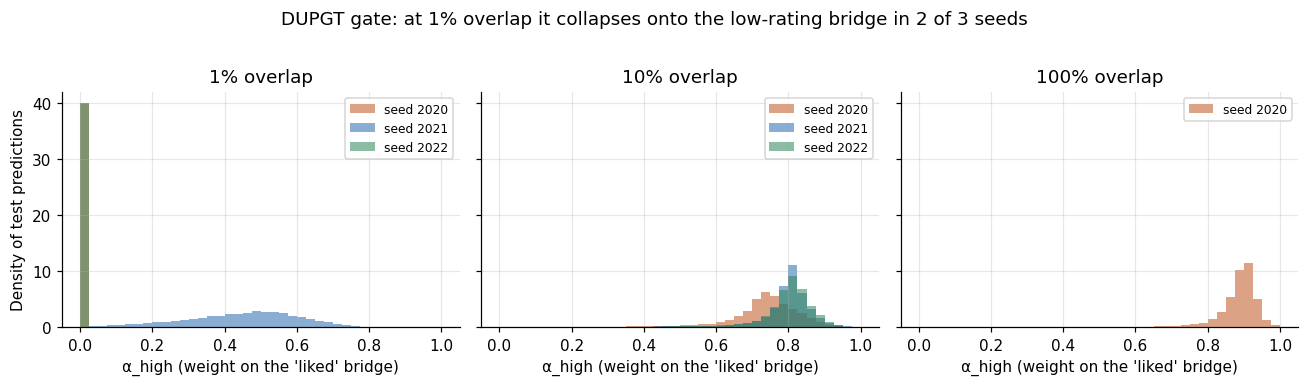

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4), sharey=True)
for axis, fraction in zip(axes, fractions):
    for seed, shade in zip(sorted(rows.seed.unique()), ("#c05621", "#2b6cb0", "#2f855a")):
        if (fraction, seed) in gate_samples:
            axis.hist(gate_samples[(fraction, seed)], bins=np.linspace(0, 1, 41), alpha=0.55, color=shade,
                      label=f"seed {seed}", density=True)
    axis.set(title=f"{fraction:.0%} overlap", xlabel="α_high (weight on the 'liked' bridge)")
    axis.legend(fontsize=8)
axes[0].set_ylabel("Density of test predictions")
fig.suptitle("DUPGT gate: at 1% overlap it collapses onto the low-rating bridge in 2 of 3 seeds", y=1.02)
fig.tight_layout(); save(fig, "05_gate_collapse"); plt.show()

**Reading the diagnostic.**
* At **1%**, in seeds 2020 and 2022, α_high ≈ 0 for every prediction. The gate has **collapsed**: all users are transferred through the low-rating bridge, and the high/low separation that defines DUPGT is switched off. Seed 2021 did not collapse, and it is also the 1% seed with the lowest error.
* At 1% the predictions are also **more spread out** than the true ratings warrant (prediction SD well above the 10%/100% runs). The bridge is over-confident with very little data, and that is what pushes RMSE above the movie average.
* Adding the semantic gate partly re-opens the collapsed gate at 1% (seeds 2021 and 2022) and narrows the over-dispersion. This is consistent with its larger, though noisy, gain at 1%.
* At 10% and 100% the gate is healthy (mean α_high ≈ 0.73–0.88, with real variation across users).

## 9. Who benefits from transfer? Error by amount of Book history (100% overlap)

,test ratings,movie average RMSE,DUPGT RMSE,gain from transfer
Book history,,,,
5–7,"127,286",1.0646,1.0501,+0.0145
8–12,"106,112",1.0525,1.0118,+0.0406
13–25,"95,800",1.0213,0.9787,+0.0426
26+,"104,420",1.0584,0.9942,+0.0643


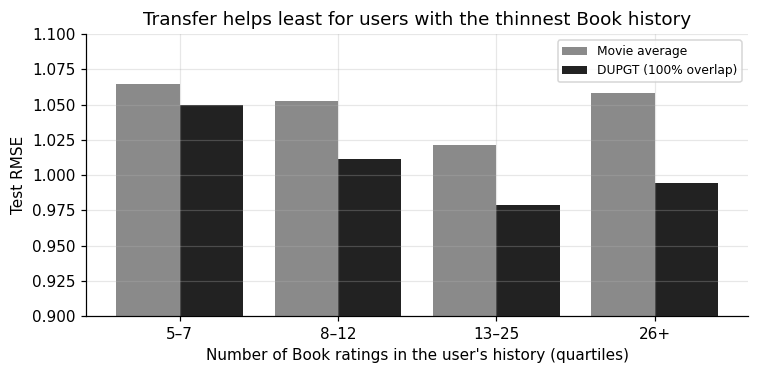

In [13]:
full = runs[(runs.overlap_fraction == 1.0) & (runs.model == "dupgt")].iloc[0]
p = predictions(full.run)
p["books"] = p.source_high_count + p.source_low_count
edges = np.quantile(p.books, [0, .25, .5, .75, 1]).astype(int)
names = [f"{edges[0]}–{edges[1]}"] + [f"{a + 1}–{b}" for a, b in zip(edges[1:-2], edges[2:-1])] + [f"{edges[-2] + 1}+"]
p["Book history"] = pd.cut(p.books, [-1, *edges[1:-1], np.inf], labels=names)
by_history = p.groupby("Book history", observed=True).apply(lambda g: pd.Series({
    "test ratings": len(g),
    "movie average RMSE": np.sqrt(((g.movie_mean - g.actual_rating) ** 2).mean()),
    "DUPGT RMSE": np.sqrt(((g.dupgt - g.actual_rating) ** 2).mean())}))
by_history["gain from transfer"] = by_history["movie average RMSE"] - by_history["DUPGT RMSE"]
display(by_history.style.format({"test ratings": "{:,.0f}", "movie average RMSE": "{:.4f}", "DUPGT RMSE": "{:.4f}",
                                  "gain from transfer": "{:+.4f}"}))
fig, axis = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(by_history))
axis.bar(x - 0.2, by_history["movie average RMSE"], 0.4, color=COLOURS["movie_mean"], label="Movie average")
axis.bar(x + 0.2, by_history["DUPGT RMSE"], 0.4, color=COLOURS["dupgt"], label="DUPGT (100% overlap)")
axis.set_xticks(x, [str(i) for i in by_history.index])
axis.set_ylim(0.9, 1.1)
axis.set(xlabel="Number of Book ratings in the user's history (quartiles)", ylabel="Test RMSE",
         title="Transfer helps least for users with the thinnest Book history")
axis.legend(fontsize=8)
fig.tight_layout(); save(fig, "06_error_by_history"); plt.show()

## 10. Conclusions

1. **Too little overlap makes transfer harmful.** With 1% of shared users (890), every DUPGT variant is worse than the movie average (RMSE ≈ 1.09–1.11 vs 1.051), and results swing strongly with which users were sampled. By 10% (8,903 users) transfer beats the baseline, and it improves again at 100%. The break-even lies somewhere between about 900 and 9,000 shared users.
2. **The failure has a visible mechanism.** At 1%, DUPGT's high/low gate collapses onto a single bridge in 2 of 3 seeds, and predictions become over-dispersed. The polarity split the model is built around stops working exactly when overlap is scarce.
3. **Semantics help a little, reliably.** Adding the Jina-embedding semantic gate lowers RMSE by about 0.004 at 10% and 100%, consistently across seeds.
4. **LLM supervision adds nothing measurable.** LLM, plain-text and shuffled teachers are within about 0.001 RMSE of each other at every overlap level and teacher weight. Scaling the text teacher 10× (to 1,988 users) changes nothing either. The teacher's effect is not personal: a shuffled profile works as well.
5. **Average gains hide many harmed users.** Even at 100% overlap, about 4 in 10 test users are worse off with transfer than with the movie average. DUPGT has no per-user mechanism to detect this and fall back.

### Why the teacher could not help (discussion)
* It is small: 1,990–19,880 synthetic pairs against tens or hundreds of thousands of real ratings.
* Its pairwise loss only says "A over B". It cannot fix a user's overall rating level, and that level dominates RMSE.
* "Retrieved vs random" pairs mainly teach "relevant beats random", which a shuffled profile teaches equally well.
* In the 20-user audit, the LLM's picks were less accurate than plain TF-IDF (46% vs 56%).

### Limitations
* The 100% batch has one seed. The 1% and 10% batches have three.
* The test split had been examined in earlier experiments, so these are follow-up results.
* Rating 3 is grouped with "low" (as in DUPGT). Histories are in file order rather than by time.